# Practical 2 - Understanding Foundation of Stats using Rating Dataset

For this practical, I'm using a dataset of professor ratings from US universities. It has info like age, gender, beauty score, evaluation score, tenure status, and number of students per course. The goal is to explore this data and answer a few basic stats questions about it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading the dataset into a dataframe so I can start working with it.

In [2]:
df = pd.read_csv("TeachingRatings.csv")

In [3]:
print(df.head())

   rownames minority  age  gender credits    beauty  eval division native  \
0         1      yes   36  female    more  0.289916   4.3    upper    yes   
1         2       no   59    male    more -0.737732   4.5    upper    yes   
2         3       no   51    male    more -0.571984   3.7    upper    yes   
3         4       no   40  female    more -0.677963   4.3    upper    yes   
4         5       no   31  female    more  1.509794   4.4    upper    yes   

  tenure  students  allstudents  prof  
0    yes        24           43     1  
1    yes        17           20     2  
2    yes        55           55     3  
3    yes        40           46     4  
4    yes        42           48     5  


In [4]:
print("Rows and columns:", df.shape)
print("\nVariables:")
print(df.columns.tolist())

Rows and columns: (463, 13)

Variables:
['rownames', 'minority', 'age', 'gender', 'credits', 'beauty', 'eval', 'division', 'native', 'tenure', 'students', 'allstudents', 'prof']


### Q1. Is this time series or cross-sectional data?

To answer this I checked if the data tracks the same professor over multiple time periods (that would make it time series), or if it's just a bunch of different professors recorded once each (that would make it cross-sectional).

In [5]:
print("Q1> Can you identify whether teachers Rating Data is a time serires or cross sectional?")
print("number of terms: ", len(df))
print("\nData types:",df.dtypes)
print("The TeachingRatings dataset is CROSS-SECTIONAL data. It contains observations of different courses/professors, rather than repeatedly observing one variable over time.")

Q1> Can you identify whether teachers Rating Data is a time serires or cross sectional?
number of terms:  463

Data types: rownames         int64
minority           str
age              int64
gender             str
credits            str
beauty         float64
eval           float64
division           str
native             str
tenure             str
students         int64
allstudents      int64
prof             int64
dtype: object
The TeachingRatings dataset is CROSS-SECTIONAL data. It contains observations of different courses/professors, rather than repeatedly observing one variable over time.


### Q2. Mean, median, min and max for students

The basic summary numbers for the "students" column — how many students were in each class on average, the middle value, and the smallest/largest class sizes.

In [6]:
print("Q2. Find the mean, median, minimum and maximum values for the students.")
students_stats = df["students"].agg(
    ["mean", "median", "min", "max"]
)

print(students_stats)

Q2. Find the mean, median, minimum and maximum values for the students.
mean       36.62419
median     23.00000
min         5.00000
max       380.00000
Name: students, dtype: float64


### Q3. Descriptive statistics table

Now a bigger summary table covering age, beauty, eval, students, and allstudents together — mean, standard deviation, min, max, and the quartiles for each one.

In [7]:
print("Q3. Produce the descriptive statistics table.")
descriptive_stats = df[
    ["age", "beauty", "eval", "students", "allstudents"]
].describe().T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

print(descriptive_stats.round(3))

Q3. Produce the descriptive statistics table.
                 N    Mean  Std. Deviation  Minimum      Q1  Median      Q3  \
age          463.0  48.365           9.803    29.00  42.000  48.000  57.000   
beauty       463.0   0.000           0.789    -1.45  -0.656  -0.068   0.546   
eval         463.0   3.998           0.555     2.10   3.600   4.000   4.400   
students     463.0  36.624          45.018     5.00  15.000  23.000  40.000   
allstudents  463.0  55.177          75.073     8.00  19.000  29.000  60.000   

             Maximum  
age            73.00  
beauty          1.97  
eval            5.00  
students      380.00  
allstudents   581.00  


### Q4. Histogram of the beauty variable

Plotting a histogram to see how the beauty scores are spread out across all the professors.

Q4. Create a histogram of the beauty variable and breifly comment on the distribution of the data. 


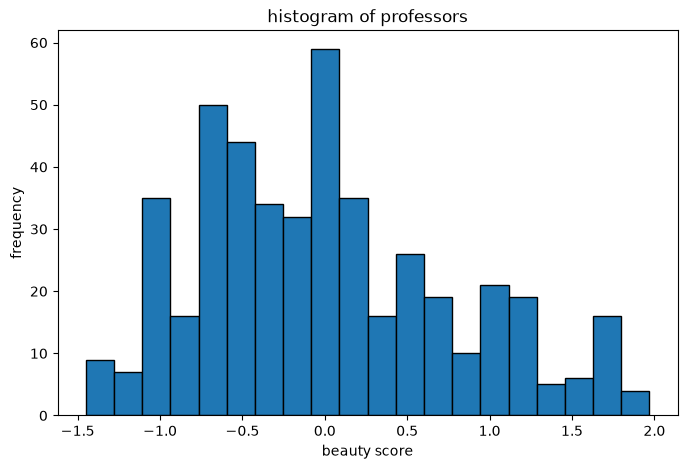

In [8]:
print("Q4. Create a histogram of the beauty variable and breifly comment on the distribution of the data. ")

plt.figure(figsize=(8,5))
plt.hist(
    df["beauty"],
         bins=20,
         edgecolor="black")
plt.xlabel("beauty score")
plt.ylabel("frequency")
plt.title("histogram of professors")
plt.show()

### Q5. Does beauty score differ by gender?

Grouping the data by gender and comparing the average beauty score and standard deviation for male vs female instructors.

In [9]:
print("Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.")
gender_stats = df.groupby("gender")["beauty"].agg(
    ["mean", "std"]
)

print(gender_stats)

Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.
            mean      std
gender                   
female  0.116109  0.81781
male   -0.084482  0.75713


### Q6. Tenure status by gender

Last question — checking what percentage of professors are tenured vs not, and thinking about whether this differs between male and female instructors.

In [10]:
print("Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?")
tenure_status = df["tenure"].value_counts(normalize=True) * 100

print(tenure_status)

Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?
tenure
yes    77.969762
no     22.030238
Name: proportion, dtype: float64


## Conclusion

Overall, this dataset gives a snapshot of 463 different courses and professors, so it's cross-sectional, not time series data. Class sizes vary quite a bit, with an average of around 37 students but a median closer to 23, so a handful of really big classes are pulling the average up. Most of the numbers (age, evaluation scores, beauty scores) look fairly normal and don't have any extreme outliers.

Looking at beauty scores by gender, female instructors had a slightly higher average than male instructors, though the difference isn't huge. For tenure, male professors had a somewhat higher tenure rate than female professors in this sample. It's a noticeable gap, but not massive, and it would take a proper statistical test to say for sure whether this difference is meaningful or could just be due to chance.

So in short: the data looks reasonably clean and normal overall, with small but real differences between male and female instructors in both beauty ratings and tenure status.